# 07 — RQ2: Do segments change which products should be removed? (cereal)

**Pipeline notebook:** 07 (work-plan step 6 of 10) · **Data:** cereal, estimation weeks 1–75 · **Models:** fitted in notebook 04, not refitted

**Research question 2:** does a segment-aware model lead to a different, and better, choice of products to remove than a segment-blind model or a simple sales rule?

Three removal lists, each removing **21 of the 207 core products (10%)**; pooled tail alternatives are never removed:

| List | How products are chosen |
|---|---|
| **Naive** | the 21 core products with the lowest observed revenue in weeks 1–75 |
| **Pooled** | greedy with the pooled model: remove one product at a time, each time the one whose removal loses the least category revenue, then recompute |
| **Segment** | the same greedy rule with the segment model |

**Fairness rule (frozen specification).** A list chosen with one model looks best when judged by that same model. Every list is therefore scored under **both** the pooled and the segment model, and both results are reported.

**Measures.** Category revenue kept (main), and cereal purchases kept (reported alongside, because notebook 06 showed that the model assumes buyers of cheap products trade up, which flatters revenue). Profit is step 7.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUTS = Path("modelling_inputs_dunnhumby")
SEGS   = Path("step7_outputs")
PARAMS = Path("outputs/choice_models/model_params.json")
OUT    = Path("outputs/removal_lists"); OUT.mkdir(parents=True, exist_ok=True)
CAT, NSEG, SHARE_REMOVED = "cereal", 4, 0.10

P = json.load(open(PARAMS)); EST_END = P["estimation_weeks"][1]
occ   = pd.read_parquet(INPUTS / f"choice_occasions_{CAT}.parquet")
aw    = pd.read_parquet(INPUTS / f"alt_week_{CAT}.parquet")
alts  = pd.read_parquet(INPUTS / f"alternatives_{CAT}.parquet")
lines = pd.read_parquet(INPUTS / f"choice_lines_{CAT}.parquet")
segs  = pd.read_parquet(SEGS / "household_segments.parquet")[["household_key", "segment", "segment_placebo"]]
est = occ[occ.week_no <= EST_END].merge(segs, on="household_key", how="inner")

## 1. Rebuild the fitted utilities (same code as notebooks 04–06)

In [2]:
alt_ids = P["alt_ids"]; J = len(alt_ids); idx = {a: i for i, a in enumerate(alt_ids)}
assert sorted(aw.alt_id.unique()) == alt_ids
REF = idx[P["reference_alt"]]; asc_cols = [i for i in range(J) if i != REF]
aw["j"] = aw.alt_id.map(idx); NW = int(aw.week_no.max())
def grid(col):
    g = np.zeros((J, NW + 1)); g[aw.j, aw.week_no] = aw[col].fillna(0).values; return g
AVAIL = np.zeros((J, NW + 1), bool); AVAIL[aw.j, aw.week_no] = aw.available.values
PRICE, DISC, DISP = grid("price"), grid("disc_depth"), grid("display_share")
A_ = alts.set_index("alt_id").loc[alt_ids]
PL, IS_TAIL = A_.is_private.values.astype(float), A_.is_tail.values
CORE = np.where(~IS_TAIL)[0]; N_REMOVE = int(round(SHARE_REMOVED * len(CORE)))

def design(A, w, s, segmented):
    asc = np.zeros((len(A), J - 1)); pos = {c: k for k, c in enumerate(asc_cols)}
    for r, a in enumerate(A):
        if a != REF: asc[r, pos[a]] = 1
    X = np.column_stack([PRICE[A, w], DISC[A, w], DISP[A, w]])
    if not segmented: return np.hstack([asc, X])
    B = np.zeros((len(A), NSEG * 3)); B[:, 3 * s:3 * s + 3] = X
    Q = np.zeros((len(A), NSEG - 1))
    if s > 0: Q[:, s - 1] = PL[A]
    return np.hstack([asc, B, Q])
def month(w): return int(((w - 1) // 4.35) % 12)

e_lines = lines[lines.week_no <= EST_END]
rev = e_lines.groupby("alt_id").spend.mean().reindex(alt_ids); REV = rev.fillna(rev.median()).values      # $ per purchase occasion
OBS_REV = e_lines.groupby("alt_id").spend.sum().reindex(alt_ids).fillna(0).values                         # observed revenue, weeks 1-75
print(f"Core products: {len(CORE)} | products removed per list: {N_REMOVE}")

Core products: 207 | products removed per list: 21


## 2. A model as a calculator: category revenue for any set of removed products

For each week and segment, the model's utilities for the available products are computed once. Removing a set of products takes them out of the choice set; the purchase stage and the product shares are then recomputed exactly (not approximated).

In [3]:
class Market:
    def __init__(self, name):
        m = P["models"][name]; self.segm = m["segmented"]; col = m["segment_column"]
        th = np.array(m["stage1_theta"]); b2 = m["stage2_params"]
        counts = est.groupby(["week_no", col]).size() if self.segm else est.groupby("week_no").size()
        self.cells = []
        for key, N in counts.items():
            w, s = (key[0], int(key[1]) - 1) if self.segm else (key, 0)
            A = np.where(AVAIL[:, w])[0]; V = design(A, w, s, self.segm) @ th
            k = f" | seg {s + 1}" if self.segm else ""
            c0 = b2[f"const{k}"] + (b2.get(f"month_{month(w)}", 0.0) if month(w) > 0 else 0.0)
            self.cells.append(dict(s=s, N=float(N), A=A, eV=np.exp(V - V.max()), vmax=V.max(), c0=c0, lam=b2[f"attractiveness{k}"]))

    def outcome(self, removed=()):
        """Expected purchases and revenue (total and per segment) with `removed` products taken out."""
        rm = np.zeros(J, bool); rm[list(removed)] = True
        pur, revn = np.zeros(NSEG), np.zeros(NSEG)
        for c in self.cells:
            keep = ~rm[c["A"]]; e = c["eV"][keep]; S = e.sum()
            iv = c["vmax"] + np.log(S); b = 1 / (1 + np.exp(-(c["c0"] + c["lam"] * iv)))
            pur[c["s"]] += c["N"] * b; revn[c["s"]] += c["N"] * b * (e @ REV[c["A"]][keep]) / S
        return pur, revn

    def greedy(self, n):
        """Remove n core products one at a time, each time the one whose removal loses least category revenue."""
        removed, path = [], []
        cand_mask = np.zeros(J, bool); cand_mask[CORE] = True
        for step in range(n):
            gain = np.zeros(J); rm = np.zeros(J, bool); rm[removed] = True
            for c in self.cells:
                A = c["A"]; keep = ~rm[A]; Ak = A[keep]; e = c["eV"][keep]; S = e.sum(); R = e @ REV[Ak]
                iv = c["vmax"] + np.log(S); b0 = 1 / (1 + np.exp(-(c["c0"] + c["lam"] * iv)))
                S2 = S - e; iv2 = c["vmax"] + np.log(np.maximum(S2, 1e-300))
                b2_ = 1 / (1 + np.exp(-(c["c0"] + c["lam"] * iv2)))
                rev_after = c["N"] * b2_ * (R - e * REV[Ak]) / np.maximum(S2, 1e-300)
                gain[Ak] += rev_after - c["N"] * b0 * R / S      # change in category revenue if each product is removed next
            gain[~cand_mask] = -np.inf; gain[removed] = -np.inf
            j = int(gain.argmax()); removed.append(j); path.append(gain[j])
        return removed, np.array(path)

MKT = {name: Market(name) for name in ["pooled", "segment"]}

## 3. Build the three lists

In [4]:
naive = list(CORE[np.argsort(OBS_REV[CORE])[:N_REMOVE]])
pooled_list, pooled_path = MKT["pooled"].greedy(N_REMOVE)
segment_list, segment_path = MKT["segment"].greedy(N_REMOVE)
LISTS = {"naive": naive, "pooled": pooled_list, "segment": segment_list}

# check: the first greedy pick equals a brute-force search over all 207 single removals
for name in ["pooled", "segment"]:
    base_rev = MKT[name].outcome()[1].sum()
    brute = max(CORE, key=lambda j: MKT[name].outcome([j])[1].sum() - base_rev)
    assert brute == LISTS[name][0], f"greedy first pick differs from brute force for {name}"
print("Greedy first picks match a brute-force search.")

ov = pd.DataFrame({a: {b: len(set(LISTS[a]) & set(LISTS[b])) for b in LISTS} for a in LISTS})
print(f"Overlap between lists (products in common, out of {N_REMOVE}):"); print(ov.to_string())

Greedy first picks match a brute-force search.
Overlap between lists (products in common, out of 21):
         naive  pooled  segment
naive       21       3        3
pooled       3      21       20
segment      3      20       21


## 4. Table 2 — how much does each list cost? (scored under both models)

In [5]:
rows = []
for ev, mk in MKT.items():
    base_p, base_r = mk.outcome()
    for name, L in LISTS.items():
        p, r = mk.outcome(L)
        removed_rev = OBS_REV[L].sum()
        rows.append(dict(list=name, scored_by=f"{ev} model",
                         category_revenue_kept_pct=100 * r.sum() / base_r.sum(), revenue_change=r.sum() - base_r.sum(),
                         purchases_kept_pct=100 * p.sum() / base_p.sum(), purchases_change=p.sum() - base_p.sum(),
                         removed_products_revenue=removed_rev,
                         share_of_removed_revenue_kept_pct=100 * (1 + (r.sum() - base_r.sum()) / removed_rev)))
table2 = pd.DataFrame(rows)
print(f"Base category revenue (2,039 households, weeks 1-75): pooled model ${MKT['pooled'].outcome()[1].sum():,.0f}, segment model ${MKT['segment'].outcome()[1].sum():,.0f}")
table2.round(2)

Base category revenue (2,039 households, weeks 1-75): pooled model $49,304, segment model $49,301


,list,scored_by,category_revenue_kept_pct,revenue_change,purchases_kept_pct,purchases_change,removed_products_revenue,share_of_removed_revenue_kept_pct
0,naive,pooled model,100.15,76.34,99.45,-87.30,1760.81,104.34
1,pooled,pooled model,102.34,1154.11,97.60,-381.23,6445.93,117.90
2,segment,pooled model,102.33,1150.69,97.77,-354.68,5972.42,119.27
3,naive,segment model,100.11,55.32,99.43,-90.94,1760.81,103.14
4,pooled,segment model,102.01,990.67,97.44,-406.51,6445.93,115.37
5,segment,segment model,102.03,999.73,97.62,-377.90,5972.42,116.74


## 5. What kind of products does each list remove?

Notebook 06 found that the model assumes buyers of cheap products trade up. This table shows whether that pushes the model-based lists towards cheap products.

In [6]:
prof = []
for name, L in LISTS.items():
    prof.append(dict(list=name, private_label_products=int(PL[L].sum()), mean_spend_per_purchase=REV[L].mean(),
                     observed_revenue_removed=OBS_REV[L].sum(), share_of_core_revenue_pct=100 * OBS_REV[L].sum() / OBS_REV[CORE].sum()))
prof.append(dict(list="all core products", private_label_products=int(PL[CORE].sum()), mean_spend_per_purchase=REV[CORE].mean(),
                 observed_revenue_removed=np.nan, share_of_core_revenue_pct=np.nan))
composition = pd.DataFrame(prof); composition.round(2)

,list,private_label_products,mean_spend_per_purchase,observed_revenue_removed,share_of_core_revenue_pct
0,naive,10,2.29,1760.81,2.36
1,pooled,19,1.79,6445.93,8.65
2,segment,19,1.76,5972.42,8.01
3,all core products,57,3.03,NaN,NaN


### Is the predicted trade-up plausible? A check against observed behaviour

The models predict that demand from the removed (mostly cheap, private-label) products moves to products averaging about $3 per purchase. The check below compares that with what the same households **already buy** in weeks 1–75: the rest of their cereal purchases.

In [7]:
seg_set = set(LISTS["segment"])
buyers = e_lines[e_lines.alt_id.map(idx).isin(seg_set)].household_key.unique()
other = e_lines[e_lines.household_key.isin(buyers) & ~e_lines.alt_id.map(idx).isin(seg_set)].copy()
other["pl"] = PL[other.alt_id.map(idx).values].astype(bool)
print(f"Households buying products on the segment list: {len(buyers):,}")
print(f"Their OTHER cereal purchases: {100 * other.loc[other.pl, 'spend'].sum() / other.spend.sum():.1f}% of spend on private label, "
      f"${other.spend.mean():.2f} average spend per purchase (removed products: ${REV[LISTS['segment']].mean():.2f})")

Households buying products on the segment list: 925
Their OTHER cereal purchases: 17.5% of spend on private label, $3.05 average spend per purchase (removed products: $1.76)


## 6. Who bears the loss? Revenue lost by segment (scored by the segment model)

In [8]:
bp, br = MKT["segment"].outcome(); rows = []
for name, L in LISTS.items():
    p, r = MKT["segment"].outcome(L)
    for s in range(NSEG):
        rows.append(dict(list=name, segment=s + 1, revenue_change=r[s] - br[s], revenue_kept_pct=100 * r[s] / br[s], purchases_kept_pct=100 * p[s] / bp[s]))
by_seg = pd.DataFrame(rows)
by_seg.pivot(index="segment", columns="list", values="revenue_kept_pct").round(2)

list,naive,pooled,segment
segment,,,
1,100.18,101.74,101.69
2,100.20,102.74,102.75
3,100.85,107.22,107.06
4,99.48,99.07,99.34


## 7. Figures

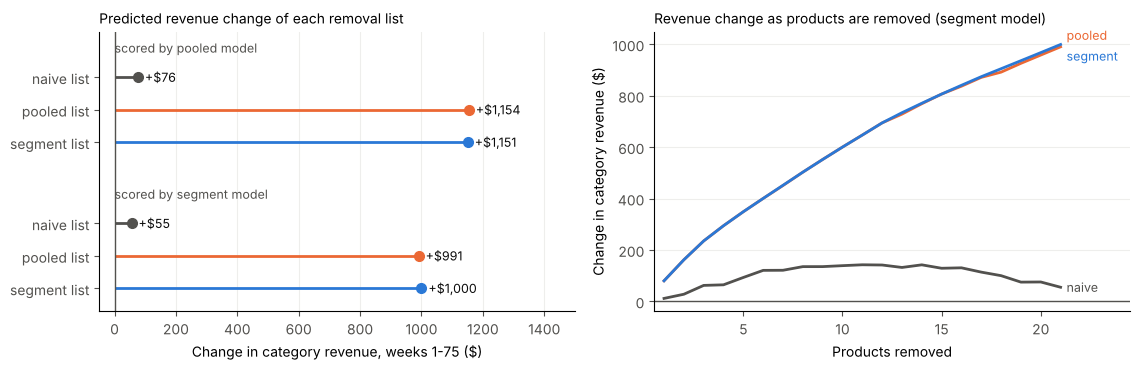

In [9]:
colors = {"naive": "#52514e", "pooled": "#eb6834", "segment": "#2a78d6"}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]; ticks, labels = [], []
for i, ev in enumerate(["pooled model", "segment model"]):
    d = table2[table2.scored_by == ev].set_index("list"); y0 = i * 4.5
    ax.text(0, y0 - 0.9, f"scored by {ev}", fontsize=9, color="#52514e", ha="left", va="center")
    for k, name in enumerate(LISTS):
        y = y0 + k; v = d.loc[name, "revenue_change"]
        ax.hlines(y, 0, v, color=colors[name], lw=2); ax.plot(v, y, "o", color=colors[name], ms=7)
        ax.text(v, y, f"  +${v:,.0f}" if v >= 0 else f"  -${-v:,.0f}", va="center", fontsize=9, color="#0b0b0b")
        ticks.append(y); labels.append(f"{name} list")
ax.set_yticks(ticks, labels); ax.set_ylim(ticks[-1] + 0.7, -1.4); ax.axvline(0, color="#52514e", lw=1)
ax.set_xlim(min(0, table2.revenue_change.min()) * 1.1 - 50, table2.revenue_change.max() * 1.3)
ax.set_xlabel("Change in category revenue, weeks 1-75 ($)"); ax.set_title("Predicted revenue change of each removal list", loc="left", fontsize=10)
ax = axes[1]; base_r = MKT["segment"].outcome()[1].sum(); ends = {}
for name, L in LISTS.items():
    cum = [MKT["segment"].outcome(L[:k])[1].sum() - base_r for k in range(1, N_REMOVE + 1)]
    ax.plot(range(1, N_REMOVE + 1), cum, color=colors[name], lw=2); ends[name] = cum[-1]
offs = {"naive": 0, "pooled": 45, "segment": -45}
for name, v in ends.items(): ax.text(N_REMOVE + 0.3, v + offs[name], name, color=colors[name], va="center", fontsize=9)
ax.axhline(0, color="#52514e", lw=1); ax.set_xlim(0.5, N_REMOVE + 3.5)
ax.set_xlabel("Products removed"); ax.set_ylabel("Change in category revenue ($)"); ax.set_title("Revenue change as products are removed (segment model)", loc="left", fontsize=10)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
    a.tick_params(colors="#52514e")
axes[0].grid(axis="x", color="#eeeeec"); axes[1].grid(axis="y", color="#eeeeec")
fig.tight_layout(); fig.savefig(OUT / "rq2_removal_lists.png", dpi=150); plt.show()

## 8. Save outputs

In [10]:
rows = []
for name, L in LISTS.items():
    for order, j in enumerate(L, 1):
        rows.append(dict(list=name, order=order, alt_id=alt_ids[j], private_label=bool(PL[j]), spend_per_purchase=REV[j], observed_revenue=OBS_REV[j]))
pd.DataFrame(rows).to_csv(OUT / "removal_lists.csv", index=False)
table2.to_csv(OUT / "table2_list_costs.csv", index=False); ov.to_csv(OUT / "list_overlap.csv")
composition.to_csv(OUT / "list_composition.csv", index=False); by_seg.to_csv(OUT / "loss_by_segment.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  list_composition.csv
  list_overlap.csv
  loss_by_segment.csv
  removal_lists.csv
  rq2_removal_lists.png
  table2_list_costs.csv


## 9. Reading the result (rules set before running)

- **Segments change the decision** if the segment list overlaps little with the pooled list **and** keeps more revenue than the pooled list *when both are scored by the pooled model as well*.
- **Segments do not change the decision** if the two model lists are largely the same, or the segment list only wins when scored by its own model.
- The **naive vs. model** comparison shows the value of modelling switching at all, whatever happens between the two model lists.
- Revenue and purchases are both reported. If they point in different directions, say so: the model predicts that some buyers of removed products trade up to pricier products, so revenue can rise while purchases fall. Section 5 checks that prediction against what the same households already buy. Step 7 (profit) tests whether the trade-up also pays once margins are applied.